# Modelling: predicting the age of an abalone

This notebook builds the model that predicts the number of rings of an abalone (its age is roughly the number of rings + 1.5 years) from its physical measurements. It follows the conclusions of the EDA notebook:

1. **Cleaning**: remove the 10 physically impossible rows.
2. **Validation protocol**: a test set stratified on `rings`, kept aside until the very end; all model choices are made by cross-validation on the training set.
3. **Feature engineering**: weight ratios and log-transformed measurements.
4. **Model selection**: from a naive baseline to linear, kernel, neighbour and tree-based models, then hyperparameter tuning and a stacking ensemble.
5. **Error analysis**: where the final model is accurate and where it is not.
6. **Interpretability, stability and fairness**: the methods of the ISAF course applied to the final model (surrogate, PDP/ICE, exact Shapley values, XPER, disagreement between methods, stability across refits, error parity between groups).

**Experiment tracking**: every model is logged to MLflow (parameters, metrics, and the trained model for the final one), so runs can be compared in the MLflow UI. MLflow stores its data in `notebooks/mlflow.db` and `notebooks/mlruns/`, which are git-ignored.

To browse the runs, start the MLflow UI from the `notebooks` folder, then open http://127.0.0.1:5001 (port 5000 is often taken by AirPlay on macOS):

```bash
cd notebooks
uv run mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5001
```

## Imports

In [1]:
import itertools
import math

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint, ttest_ind, uniform
from sklearn.base import BaseEstimator, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    StackingRegressor,
)
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
    RepeatedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    SplineTransformer,
    StandardScaler,
)
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, plot_tree

sns.set_theme(style="whitegrid", palette="deep")

2026/10/22 12:51:25 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/ethanbenhamou/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## Configuration

In [2]:
DATA_PATH = "../data/abalone.csv"
TARGET = "rings"
CATEGORICAL_FEATURE = "sex"
PART_WEIGHTS = ["shucked_weight", "viscera_weight", "shell_weight"]
MEASUREMENTS = ["length", "diameter", "height", "whole_weight", *PART_WEIGHTS]

# Physical consistency rules (see the EDA)
MIN_HEIGHT_RATIO = 0.05  # height / length
MAX_HEIGHT_RATIO = 0.6

TEST_SIZE = 0.2
N_STRATIFICATION_BINS = 10
RANDOM_STATE = 42

# 5-fold cross-validation repeated 3 times: the scores of the models are close, so
# repeating the folds makes the comparison less dependent on a lucky split
CV = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
TUNING_CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
N_TUNING_ITERATIONS = 40
SCORING = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}

MLFLOW_TRACKING_URI = "sqlite:///mlflow.db"
MLFLOW_EXPERIMENT_NAME = "abalone-age-prediction"

## Data

The dataset is the `abalone.csv` file from Kaggle, saved in the git-ignored `data/` folder. Column names are converted to snake_case (e.g. `Whole weight` becomes `whole_weight`) to make them easier to use in code.

In [3]:
def load_data(path: str) -> pd.DataFrame:
    """Load the abalone dataset and convert its column names to snake_case."""
    df = pd.read_csv(path)
    df.columns = df.columns.str.lower().str.replace(" ", "_")
    return df


df = load_data(DATA_PATH)
print(f"{df.shape[0]} abalones, {df.shape[1]} columns")
df.head()

4177 abalones, 9 columns


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


## Cleaning

The EDA found 10 rows (0.24%) that are physically impossible, and therefore data entry errors:
- a dimension equal to zero;
- a `diameter` larger than the `length`, which is by definition the longest measurement;
- a part (shucked, viscera or shell weight) heavier than the whole abalone;
- an absurd `height` / `length` ratio (the 1st-99th percentile range is [0.19, 0.36]).

The same rules will be reused to validate the inputs of the prediction API.

In [4]:
def find_invalid_rows(df: pd.DataFrame) -> pd.Series:
    """Flag the rows that violate a physical constraint of the measurements."""
    dimensions = df[["length", "diameter", "height"]]
    height_ratio = df["height"] / df["length"]
    return (
        (dimensions <= 0).any(axis=1)
        | (df["diameter"] > df["length"])
        | df[PART_WEIGHTS].gt(df["whole_weight"], axis=0).any(axis=1)
        | ~height_ratio.between(MIN_HEIGHT_RATIO, MAX_HEIGHT_RATIO)
    )


def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """Drop the physically impossible rows."""
    return df[~find_invalid_rows(df)].reset_index(drop=True)


clean_df = clean_data(df)
print(f"Removed {len(df) - len(clean_df)} rows, {len(clean_df)} abalones left")

Removed 10 rows, 4167 abalones left


## Train / test split

20% of the data is kept aside as a test set and is only used once, to evaluate the final model. The target has very thin tails (only 17 abalones with 3 rings or fewer), so the split is **stratified on deciles of `rings`**: both sets get the same share of young and old abalones.

In [5]:
def split_data(
    df: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Split the dataset into train and test sets, stratified on the target."""
    features = df.drop(columns=TARGET)
    target = df[TARGET]
    target_bins = pd.qcut(
        target, N_STRATIFICATION_BINS, labels=False, duplicates="drop"
    )
    return train_test_split(
        features,
        target,
        test_size=TEST_SIZE,
        stratify=target_bins,
        random_state=RANDOM_STATE,
    )


X_train, X_test, y_train, y_test = split_data(clean_df)
print(f"Training set: {len(X_train)} rows, test set: {len(X_test)} rows")
pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(2).T

Training set: 3333 rows, test set: 834 rows


,count,mean,std,min,25%,50%,75%,max
train,3333.0,9.94,3.21,1.0,8.0,9.0,11.0,29.0
test,834.0,9.94,3.28,3.0,8.0,9.0,11.0,24.0


## Feature engineering and preprocessing

Every transformation is part of a scikit-learn `Pipeline`. The pipeline is fitted on the training data only (inside each cross-validation fold), which prevents any leakage from the validation data, and the whole pipeline, encoder included, can be saved as a single object and reused as-is by the prediction API.

The EDA suggests two transformations:
- **Weight ratios**: at equal total weight, abalones with more meat are younger (correlation of -0.35 between `shucked_weight / whole_weight` and `rings`). The share of each part in the whole weight is a cheap and informative feature.
- **Log of the measurements**: the relationships between the measurements are multiplicative (weight ∝ length³), so the log linearises them and raises their linear correlation with `rings`. This only matters for the models sensitive to the scale of the features (linear, kernel and neighbour models); trees are invariant to monotonic transformations.

`sex` is one-hot encoded and the numerical features are standardised. `handle_unknown="ignore"` makes the encoder robust to an unexpected category at prediction time.

In [6]:
def add_weight_ratios(features: pd.DataFrame) -> pd.DataFrame:
    """Add the share of each part (meat, viscera, shell) in the whole weight."""
    # NumPy arrays are assigned by position, which stays correct even if the index
    # has duplicates (a join on the index would multiply the rows)
    whole_weight = features["whole_weight"].to_numpy()
    return features.assign(
        **{
            f"{part}_ratio": features[part].to_numpy() / whole_weight
            for part in PART_WEIGHTS
        }
    )


def log_measurements(features: pd.DataFrame) -> pd.DataFrame:
    """Replace the measurements by their logarithm, which linearises them."""
    return features.assign(
        **{column: np.log(features[column].to_numpy()) for column in MEASUREMENTS}
    )


def build_preprocessor(log_features: bool) -> Pipeline:
    """Build the feature engineering, encoding and scaling steps."""
    steps = [FunctionTransformer(add_weight_ratios)]
    if log_features:
        steps.append(FunctionTransformer(log_measurements))
    encoder = ColumnTransformer(
        [
            (
                "one_hot",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                [CATEGORICAL_FEATURE],
            )
        ],
        remainder=StandardScaler(),
        verbose_feature_names_out=False,
    )
    steps.append(encoder)
    pipeline = make_pipeline(*steps)
    pipeline.set_output(transform="pandas")
    return pipeline


build_preprocessor(log_features=True).fit_transform(X_train).head()

,sex_F,sex_I,sex_M,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,shucked_weight_ratio,viscera_weight_ratio,shell_weight_ratio
2947,0.0,0.0,1.0,0.909214,0.958942,1.176652,1.143811,1.074077,1.352465,1.128356,-0.287817,1.326093,-0.320805
4075,0.0,0.0,1.0,0.519027,0.891883,0.564988,0.760054,0.979607,0.642093,0.572595,1.743443,-0.627827,-1.064863
1480,1.0,0.0,0.0,0.550545,0.535545,0.260618,0.511483,0.579005,0.537186,0.464882,0.513756,0.120010,-0.381684
1196,0.0,0.0,1.0,1.262181,1.152642,1.096338,1.358995,1.554056,1.260465,1.223384,1.696745,-0.471373,-0.914959
3696,1.0,0.0,0.0,1.021445,1.089275,1.254933,0.977933,0.987779,1.005808,0.978759,0.210539,0.181733,-0.215176


## Evaluation protocol

Each candidate is evaluated by 5-fold cross-validation repeated 3 times on the training set, with three metrics:
- **RMSE** (root mean squared error) and **MAE** (mean absolute error), both in number of rings: the lower, the better. RMSE penalises large errors more, so it is dominated by the old abalones.
- **R²**: the share of the variation in the number of rings that the model explains (1 is perfect).

Each evaluation is logged to MLflow as one run.

In [7]:
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

cv_results: dict[str, pd.DataFrame] = {}


def cross_validate_model(
    name: str, model: BaseEstimator, params: dict | None = None
) -> pd.Series:
    """Cross-validate a model on the training set and log the scores to MLflow."""
    scores = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    fold_scores = pd.DataFrame({metric: scores[f"test_{metric}"] for metric in SCORING})
    # scikit-learn maximises scores, so the errors are returned as negative values
    fold_scores[["rmse", "mae"]] *= -1
    cv_results[name] = fold_scores

    summary = fold_scores.agg(["mean", "std"])
    with mlflow.start_run(run_name=name):
        mlflow.set_tag("stage", "model_selection")
        mlflow.log_param("model", name)
        mlflow.log_params(params or {})
        mlflow.log_metrics(
            {
                f"cv_{metric}_{stat}": summary.loc[stat, metric]
                for metric in SCORING
                for stat in ("mean", "std")
            }
        )
    return summary.loc["mean"]


def summarise_cv_results() -> pd.DataFrame:
    """Summarise the cross-validation scores of all the evaluated models."""
    summary = pd.DataFrame(
        {
            name: {
                "rmse": scores["rmse"].mean(),
                "rmse_std": scores["rmse"].std(),
                "mae": scores["mae"].mean(),
                "r2": scores["r2"].mean(),
            }
            for name, scores in cv_results.items()
        }
    ).T
    return summary.sort_values("rmse").round(3)

2026/10/22 12:51:27 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/22 12:51:27 INFO mlflow.store.db.utils: Updating database tables


2026/10/22 12:51:27 INFO mlflow.tracking.fluent: Experiment with name 'abalone-age-prediction' does not exist. Creating a new experiment.


## Baselines

Two reference points that any useful model has to beat:
- a **naive model** that always predicts the mean number of rings of the training set;
- a **linear regression** on the raw features, the first model of this project.

In [8]:
def make_model(
    regressor: BaseEstimator, log_features: bool = False, log_target: bool = False
) -> BaseEstimator:
    """Chain the preprocessing and a regressor, optionally predicting log(rings)."""
    model = make_pipeline(build_preprocessor(log_features), regressor)
    if log_target:
        # Fit on log(rings), which is almost symmetric, and predict exp of the output
        return TransformedTargetRegressor(model, func=np.log, inverse_func=np.exp)
    return model


baseline_models = {
    "naive (mean)": make_model(DummyRegressor()),
    "linear regression": make_model(LinearRegression()),
}
for name, model in baseline_models.items():
    cross_validate_model(name, model)
summarise_cv_results()

,rmse,rmse_std,mae,r2
linear regression,2.141,0.064,1.550,0.553
naive (mean),3.210,0.126,2.355,-0.001


## Comparing model families

The candidates cover the main families, each with sensible default hyperparameters:

| Model | Why it is a candidate |
|---|---|
| Linear regression on log features and log target | The EDA showed that the log-log relationships are the most linear (correlation of 0.74 for `shell_weight`) |
| Ridge on splines | Splines let a linear model fit a smooth non-linear curve per feature; Ridge handles the strong collinearity |
| SVR (RBF kernel) | Smooth non-linear model with built-in regularisation, robust to outliers thanks to its ε-insensitive loss |
| k-nearest neighbours | Non-parametric: the age of similar abalones |
| Random forest / Extra trees | Capture non-linearities and the `sex` interactions found in the EDA without manual work |
| Gradient boosting | Usually the strongest model on tabular data |

In [9]:
candidate_models = {
    "linear regression (log)": make_model(
        LinearRegression(), log_features=True, log_target=True
    ),
    "ridge on splines (log)": make_model(
        make_pipeline(SplineTransformer(), RidgeCV(alphas=np.logspace(-3, 3, 20))),
        log_features=True,
        log_target=True,
    ),
    "svr (log)": make_model(SVR(), log_features=True),
    "k-nearest neighbours (log)": make_model(
        KNeighborsRegressor(n_neighbors=25, weights="distance"), log_features=True
    ),
    "random forest": make_model(
        RandomForestRegressor(
            n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE
        )
    ),
    "extra trees": make_model(
        ExtraTreesRegressor(
            n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE
        )
    ),
    "gradient boosting": make_model(
        HistGradientBoostingRegressor(random_state=RANDOM_STATE)
    ),
}
for name, model in candidate_models.items():
    cross_validate_model(name, model)
summarise_cv_results()

,rmse,rmse_std,mae,r2
ridge on splines (log),2.075,0.061,1.451,0.580
extra trees,2.081,0.059,1.464,0.578
svr (log),2.090,0.074,1.437,0.575
random forest,2.093,0.046,1.487,0.573
k-nearest neighbours (log),2.100,0.067,1.458,0.570
linear regression (log),2.130,0.078,1.486,0.558
linear regression,2.141,0.064,1.550,0.553
gradient boosting,2.153,0.055,1.528,0.548
naive (mean),3.210,0.126,2.355,-0.001


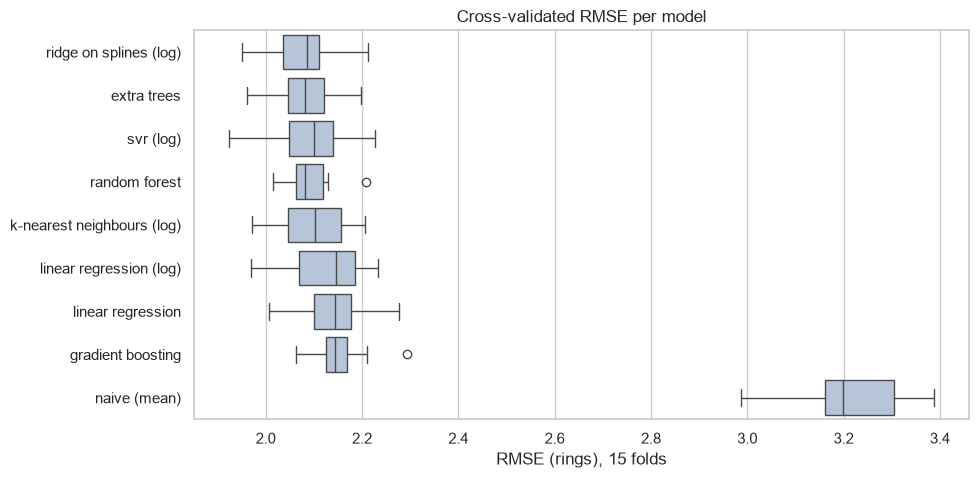

In [10]:
def plot_cv_results() -> None:
    """Plot the distribution of the cross-validated RMSE of each model."""
    order = summarise_cv_results().index
    rmse_per_fold = pd.DataFrame({name: cv_results[name]["rmse"] for name in order})
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(order) + 1))
    sns.boxplot(data=rmse_per_fold, orient="h", ax=ax, color="lightsteelblue")
    ax.set(xlabel="RMSE (rings), 15 folds", title="Cross-validated RMSE per model")
    plt.show()


plot_cv_results()

**Conclusions**
- Every model clearly beats the naive baseline (RMSE ≈ 3.2), and the non-linear models beat the plain linear regression (RMSE ≈ 2.14).
- Taking the log of the features and of the target helps the linear regression, as the EDA predicted, but only slightly: a linear model cannot capture the curvature of the relationships.
- The best models (ridge on splines, extra trees, SVR, random forest) are very close to each other (RMSE between 2.07 and 2.09), and their differences are smaller than the fold-to-fold variation. Choosing one of them on these scores alone would be fitting the noise: they need to be tuned before being compared, and since they belong to different families they make different errors, which makes them good candidates for an ensemble.
- Out-of-the-box gradient boosting is even worse than the linear regression: its defaults (deep trees, high learning rate) are designed for larger datasets and overfit here, so it needs stronger regularisation.

## Hyperparameter tuning

The four most promising families are tuned with a randomised search (5-fold cross-validation on the training set, optimising the RMSE). The tuned models are then evaluated with the same repeated cross-validation as before.

The tuned scores are slightly optimistic, since the hyperparameters were chosen on the same training data. This is why the test set stays untouched until the final evaluation.

In [11]:
search_spaces = {
    "svr (log, tuned)": (
        make_model(SVR(), log_features=True),
        {
            "svr__C": loguniform(0.3, 100),
            "svr__epsilon": uniform(0, 1.5),
            "svr__gamma": loguniform(0.005, 1),
        },
    ),
    "ridge on splines (log, tuned)": (
        make_model(
            make_pipeline(SplineTransformer(), RidgeCV(alphas=np.logspace(-3, 3, 20))),
            log_features=True,
        ),
        {
            "pipeline-2__splinetransformer__n_knots": randint(3, 10),
            "pipeline-2__splinetransformer__degree": randint(1, 4),
        },
    ),
    "random forest (tuned)": (
        make_model(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)),
        {
            "randomforestregressor__min_samples_leaf": randint(1, 30),
            "randomforestregressor__max_features": uniform(0.2, 0.8),
        },
    ),
    "gradient boosting (tuned)": (
        make_model(
            HistGradientBoostingRegressor(
                max_iter=1000, early_stopping=True, random_state=RANDOM_STATE
            )
        ),
        {
            "histgradientboostingregressor__learning_rate": loguniform(0.01, 0.2),
            "histgradientboostingregressor__max_leaf_nodes": randint(4, 40),
            "histgradientboostingregressor__min_samples_leaf": randint(10, 120),
            "histgradientboostingregressor__l2_regularization": loguniform(1e-3, 10),
            "histgradientboostingregressor__max_features": uniform(0.3, 0.7),
        },
    ),
}


def tune_model(model: BaseEstimator, search_space: dict) -> tuple[BaseEstimator, dict]:
    """Search the best hyperparameters of a model by cross-validation."""
    search = RandomizedSearchCV(
        model,
        search_space,
        n_iter=N_TUNING_ITERATIONS,
        cv=TUNING_CV,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )
    search.fit(X_train, y_train)
    return search.best_estimator_, search.best_params_


tuned_models: dict[str, BaseEstimator] = {}
for name, (model, search_space) in search_spaces.items():
    tuned_models[name], best_params = tune_model(model, search_space)
    print(f"{name}: {best_params}")
    cross_validate_model(name, tuned_models[name], best_params)

svr (log, tuned): {'svr__C': np.float64(7.819078381298658), 'svr__epsilon': np.float64(1.1564507699318414), 'svr__gamma': np.float64(0.06842400382476596)}


ridge on splines (log, tuned): {'pipeline-2__splinetransformer__degree': 3, 'pipeline-2__splinetransformer__n_knots': 4}


random forest (tuned): {'randomforestregressor__max_features': np.float64(0.5961415280890161), 'randomforestregressor__min_samples_leaf': 15}


gradient boosting (tuned): {'histgradientboostingregressor__l2_regularization': np.float64(0.1707685960990951), 'histgradientboostingregressor__learning_rate': np.float64(0.033527639013957666), 'histgradientboostingregressor__max_features': np.float64(0.3454245729762871), 'histgradientboostingregressor__max_leaf_nodes': 15, 'histgradientboostingregressor__min_samples_leaf': 48}


## Stacking ensemble

A stacking ensemble combines the predictions of the tuned models: each base model is trained on the training set, and a Ridge regression learns how much weight to give to each of them, using out-of-fold predictions so that it does not reward overfitting. The ensemble benefits from the fact that the models come from different families and make different errors.

In [12]:
def build_stacking_model(base_models: dict[str, BaseEstimator]) -> StackingRegressor:
    """Combine the base models with a Ridge regression trained on their predictions."""
    return StackingRegressor(
        estimators=list(base_models.items()),
        final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 20)),
        cv=TUNING_CV,
        n_jobs=-1,
    )


stacking_model = build_stacking_model(tuned_models)
cross_validate_model("stacking ensemble", stacking_model)
summarise_cv_results()

,rmse,rmse_std,mae,r2
stacking ensemble,2.041,0.062,1.442,0.594
"svr (log, tuned)",2.062,0.075,1.435,0.586
"ridge on splines (log, tuned)",2.065,0.065,1.476,0.584
random forest (tuned),2.073,0.052,1.462,0.581
ridge on splines (log),2.075,0.061,1.451,0.580
gradient boosting (tuned),2.077,0.061,1.464,0.580
extra trees,2.081,0.059,1.464,0.578
svr (log),2.090,0.074,1.437,0.575
random forest,2.093,0.046,1.487,0.573
k-nearest neighbours (log),2.100,0.067,1.458,0.570


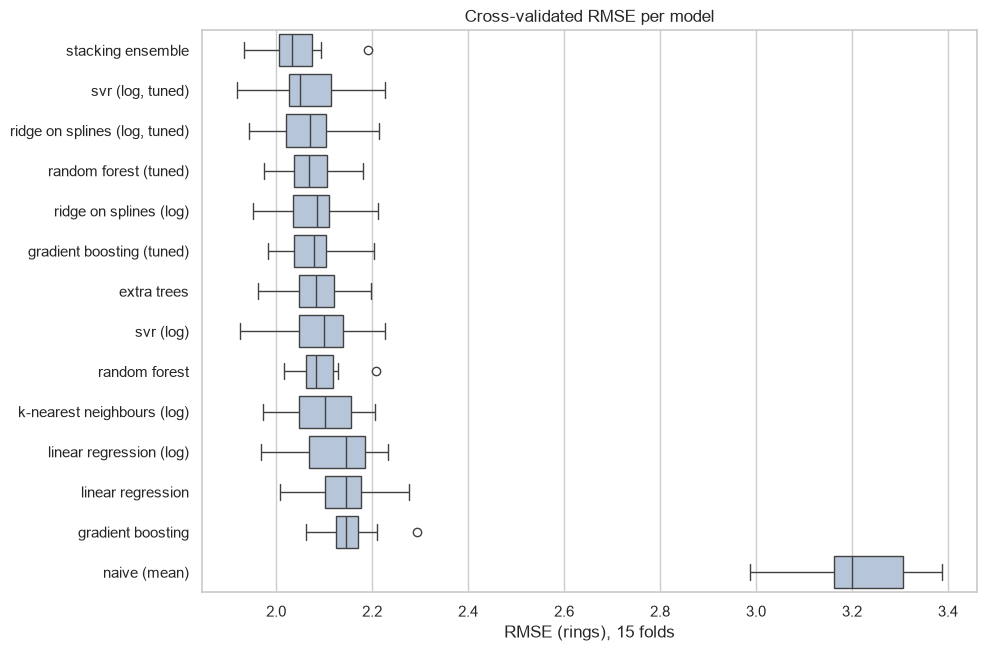

In [13]:
plot_cv_results()

**Conclusions**
- Tuning improves every family, gradient boosting the most (RMSE from 2.15 to 2.08), but the tuned models still end up within 0.02 rings of each other: the data, not the model, is the limit.
- The **stacking ensemble is the best model** (RMSE 2.04, R² 0.59), ahead of every individual model. Its MAE is on par with the tuned SVR, the best model on that metric. It is chosen as the final model.

## Final evaluation on the test set

The final model is trained on the whole training set and evaluated **once** on the test set, alongside the linear regression baseline. The final model, its parameters and its metrics are logged to MLflow.

In [14]:
def evaluate_model(
    model: BaseEstimator, features: pd.DataFrame, target: pd.Series
) -> dict[str, float]:
    """Compute the model's regression metrics on the given data."""
    predictions = model.predict(features)
    return {
        "rmse": root_mean_squared_error(target, predictions),
        "mae": mean_absolute_error(target, predictions),
        "r2": r2_score(target, predictions),
    }


final_model = stacking_model.fit(X_train, y_train)
baseline_model = baseline_models["linear regression"].fit(X_train, y_train)

test_metrics = evaluate_model(final_model, X_test, y_test)
baseline_test_metrics = evaluate_model(baseline_model, X_test, y_test)

with mlflow.start_run(run_name="final model: stacking ensemble"):
    mlflow.set_tag("stage", "final")
    mlflow.log_params(
        {
            "model": "StackingRegressor",
            "base_models": ", ".join(tuned_models),
            "test_size": TEST_SIZE,
            "random_state": RANDOM_STATE,
        }
    )
    mlflow.log_metrics({f"test_{name}": value for name, value in test_metrics.items()})
    # cloudpickle also saves the feature engineering functions defined in this
    # notebook, which the default skops format refuses to load
    mlflow.sklearn.log_model(
        final_model,
        name="model",
        input_example=X_train.head(),
        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
    )

pd.DataFrame(
    {"linear regression": baseline_test_metrics, "stacking ensemble": test_metrics}
).T.round(3)

2026/10/22 12:52:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/22 12:52:13 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


,rmse,mae,r2
linear regression,2.241,1.627,0.531
stacking ensemble,2.090,1.496,0.592


In [15]:
weights = pd.Series(
    final_model.final_estimator_.coef_, index=list(tuned_models), name="weight"
)
weights.round(3).sort_values(ascending=False)

svr (log, tuned)                 0.472
gradient boosting (tuned)        0.392
ridge on splines (log, tuned)    0.294
random forest (tuned)           -0.106
Name: weight, dtype: float64

**Conclusions**
- On unseen data, the stacking ensemble reduces the RMSE by about 7% (2.24 → 2.09) and the MAE by about 8% (1.63 → 1.50) compared with the linear regression, and raises the R² from 0.53 to 0.59.
- Both models score slightly worse on the test set than in cross-validation, by a similar margin: this test set is a bit harder than average, and the gain of the ensemble is consistent with the cross-validation, so the tuning did not overfit.
- The ensemble relies mostly on the SVR, then on the gradient boosting and the ridge on splines. The random forest gets a small negative weight: its predictions are very close to those of the gradient boosting, so the Ridge uses it as a small correction rather than as an independent opinion.

## Error analysis

A single score hides where the model is good and where it is not. The EDA found that the measurements predict age much better for infants than for adults, and that the noise grows with age.

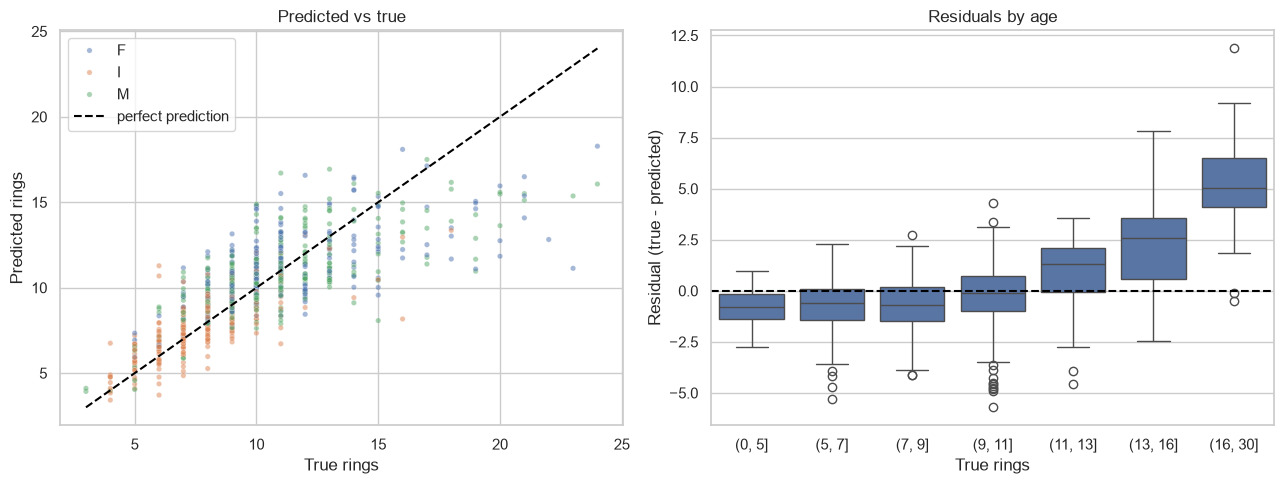

In [16]:
predictions = final_model.predict(X_test)
residuals = y_test - predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=y_test, y=predictions, hue=X_test["sex"], alpha=0.5, s=15, ax=axes[0])
limits = [y_test.min(), y_test.max()]
axes[0].plot(limits, limits, color="black", linestyle="--", label="perfect prediction")
axes[0].set(xlabel="True rings", ylabel="Predicted rings", title="Predicted vs true")
axes[0].legend()

sns.boxplot(x=pd.cut(y_test, [0, 5, 7, 9, 11, 13, 16, 30]), y=residuals, ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(
    xlabel="True rings", ylabel="Residual (true - predicted)", title="Residuals by age"
)
plt.tight_layout()
plt.show()

In [17]:
def summarise_errors(errors: pd.Series, groups: pd.Series) -> pd.DataFrame:
    """Compute the bias, MAE and share of predictions within 1 or 2 rings per group."""
    absolute_errors = errors.abs()
    return pd.DataFrame(
        {
            "count": errors.groupby(groups, observed=True).size(),
            "bias": errors.groupby(groups, observed=True).mean(),
            "mae": absolute_errors.groupby(groups, observed=True).mean(),
            "within 1 ring": absolute_errors.le(1).groupby(groups).mean(),
            "within 2 rings": absolute_errors.le(2).groupby(groups).mean(),
        }
    ).round(2)


age_group = X_test["sex"].eq("I").map({True: "infant", False: "adult"})
rings_group = pd.cut(
    y_test, [0, 7, 10, 13, 30], labels=["≤ 7", "8-10", "11-13", "≥ 14"]
)
pd.concat(
    {
        "all": summarise_errors(residuals, pd.Series("all", index=residuals.index)),
        "age group": summarise_errors(residuals, age_group),
        "rings": summarise_errors(residuals, rings_group),
    }
)

count  bias   mae  within 1 ring  within 2 rings
all       all       834  0.07  1.50           0.47            0.75
age group adult     574  0.08  1.72           0.40            0.68
          infant    260  0.05  1.01           0.62            0.91
rings     ≤ 7       175 -0.75  1.08           0.59            0.87
          8-10      370 -0.60  1.13           0.56            0.85
          11-13     194  0.43  1.46           0.37            0.70
          ≥ 14       95  3.45  3.75           0.13            0.23

**Conclusions**
- Overall, the model is unbiased: 47% of the predictions are within 1 ring of the truth, and 75% within 2 rings.
- The errors are **much smaller for infants than for adults** (MAE of 1.0 versus 1.7 rings, 91% versus 68% of predictions within 2 rings), as the EDA predicted: once an abalone is mature, its size says little about its age.
- The model **regresses towards the mean**: it slightly overestimates the young abalones (by 0.75 rings for 7 rings or fewer) and strongly underestimates the old ones (by 3.5 rings on average for 14 rings or more). This is not a bug that more tuning can fix: old abalones have stopped growing, so they look like middle-aged ones. Predicting their age would require other information (e.g. location, environment, or the shell structure).

## Feature importance

Permutation importance measures how much the test RMSE increases when the values of one input are randomly shuffled, which breaks its link with the target. It is computed on the raw inputs of the pipeline, so it accounts for every feature derived from them.

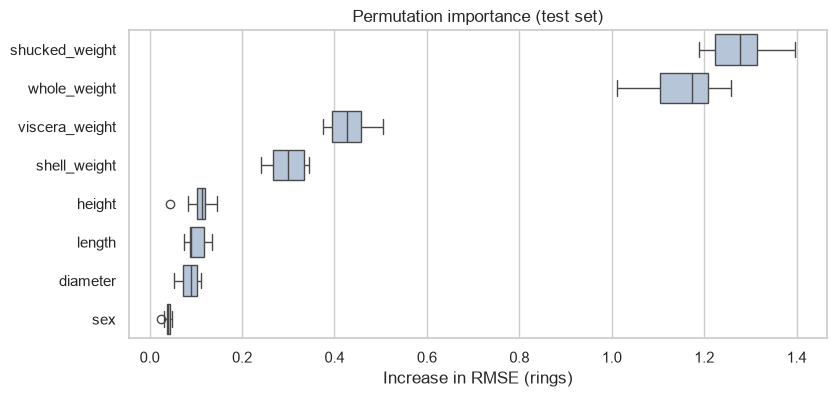

In [18]:
importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance_df = pd.DataFrame(importance.importances.T, columns=X_test.columns).reindex(
    columns=X_test.columns[np.argsort(importance.importances_mean)[::-1]]
)

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=importance_df, orient="h", ax=ax, color="lightsteelblue")
ax.set(xlabel="Increase in RMSE (rings)", title="Permutation importance (test set)")
plt.show()

**Conclusions**
- `shucked_weight` and `whole_weight` matter by far the most (shuffling either of them increases the RMSE by more than 1 ring). It is their combination that carries the information: the share of meat in the abalone decreases with age (see the EDA), which a single size measurement cannot capture.
- `viscera_weight` and `shell_weight` come next. The size measurements (`length`, `diameter`, `height`) add little once the weights are known, since they are almost perfectly correlated with them.
- `sex` has a low importance: the EDA showed that infants are younger at equal size, but this information is largely already contained in the weights and their ratios.

# Interpretability, stability and fairness of the final model

The stacking ensemble is a black box: four models of different families combined by a Ridge regression. Before deploying it, this section applies the methods of the **ISAF course** (*Interpretability, Stability and Algorithmic Fairness*, HEC Paris) to answer four questions:

1. **What does the model do globally?** Global surrogate, partial dependence and individual conditional expectation (ICE) curves.
2. **Why this prediction for this abalone, and where does the performance come from?** Exact Shapley values (SHAP) and their counterpart for the performance metric (XPER).
3. **Do the explanations agree?** The disagreement problem between explanation methods.
4. **Is the model stable, and are its errors fair across groups?** Refitting on subsamples of the training set, and error parity tests between sexes.

In [19]:
FEATURES = X_train.columns.tolist()
SURROGATE_MAX_DEPTH = 3
N_EXPLAINED = 150  # test abalones explained with Shapley values
N_BACKGROUND = 40  # training abalones used to integrate out the absent features
N_SUBSAMPLES = 8
SUBSAMPLE_FRACTION = 0.8
SIGNIFICANCE_LEVEL = 0.05

test_predictions = final_model.predict(X_test)

## Global surrogate

A global surrogate is an interpretable model trained to reproduce the **predictions of the black box**, not the true target: $g = \arg\min_{g \in G} \sum_i (\hat y_i - g(x_i))^2$. Here, a decision tree of depth 3. As the course insists, a surrogate must always come with its **fidelity** (the R² between its predictions and those of the black box), which must not be confused with its performance (the R² against the true number of rings).

Fidelity to the stacking ensemble (test R²): 0.720
Performance on the true rings (test R²): 0.428


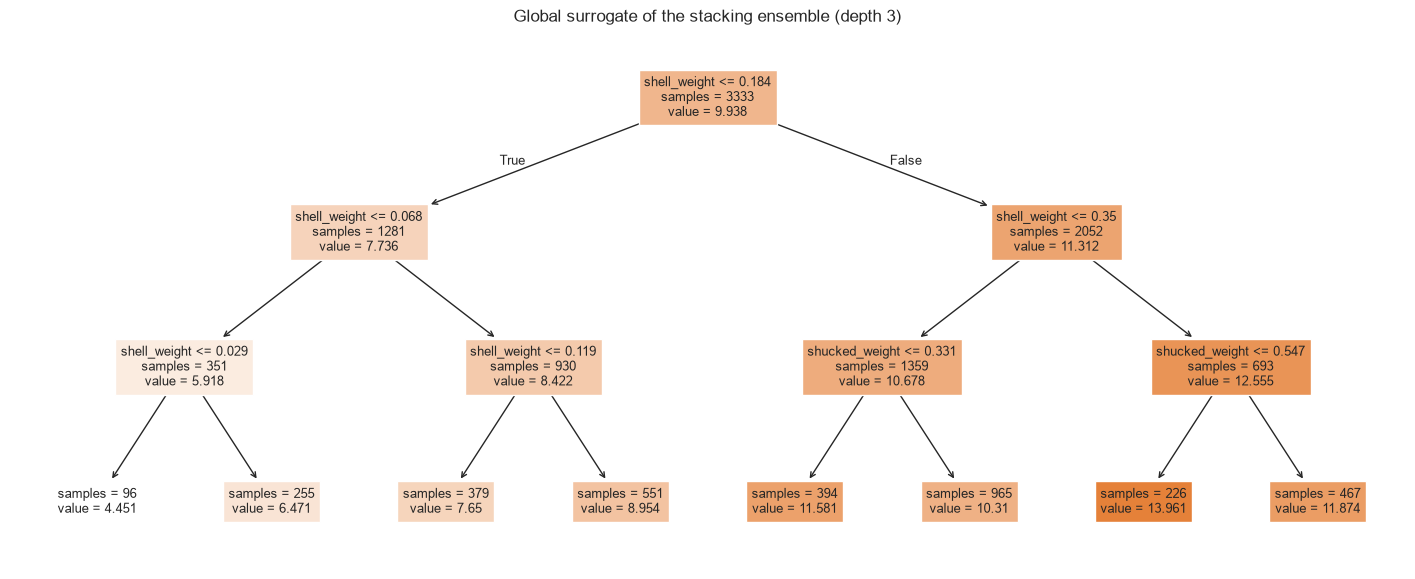

In [20]:
def fit_global_surrogate(
    model: BaseEstimator, features: pd.DataFrame, max_depth: int
) -> Pipeline:
    """Fit a shallow decision tree that imitates the predictions of a model."""
    surrogate = make_pipeline(
        ColumnTransformer(
            [("one_hot", OneHotEncoder(sparse_output=False), [CATEGORICAL_FEATURE])],
            remainder="passthrough",
            verbose_feature_names_out=False,
        ),
        DecisionTreeRegressor(max_depth=max_depth, random_state=RANDOM_STATE),
    )
    return surrogate.fit(features, model.predict(features))


surrogate = fit_global_surrogate(final_model, X_train, SURROGATE_MAX_DEPTH)
surrogate_predictions = surrogate.predict(X_test)
print(
    f"Fidelity to the stacking ensemble (test R²): "
    f"{r2_score(test_predictions, surrogate_predictions):.3f}"
)
surrogate_performance = r2_score(y_test, surrogate_predictions)
print(f"Performance on the true rings (test R²): {surrogate_performance:.3f}")

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    surrogate[-1],
    feature_names=surrogate[0].get_feature_names_out(),
    filled=True,
    impurity=False,
    precision=3,
    fontsize=9,
    ax=ax,
)
ax.set_title(f"Global surrogate of the stacking ensemble (depth {SURROGATE_MAX_DEPTH})")
plt.show()

**Conclusions**

- The tree reproduces the stacking ensemble with a fidelity of 0.72: **28% of the variance of the predictions is not captured**, and its own R² against the true rings is only 0.43 (versus 0.59 for the ensemble).
- It reads simply: the shell weight sorts the abalones by age, then, among heavy abalones, **more meat means younger** (13.96 rings when `shucked_weight` ≤ 0.547 versus 11.87 above, for shells heavier than 0.35). This is the effect of the share of meat found in the EDA.
- But it only uses two features, whereas the other methods below show that the ensemble relies mostly on `whole_weight` and `shucked_weight`. This is the "illusion of interpretability" the course warns about: the tree explains a simpler model that resembles the ensemble at 72%, not the ensemble itself.

## Partial dependence (PDP) and individual conditional expectation (ICE)

The partial dependence of a feature $x_s$ is the average prediction when $x_s$ is set to the same value for every abalone, the other features keeping their values: $\hat{pd}_s(x_s) = \frac{1}{n} \sum_i \hat f(x_s, x_c^{(i)})$. ICE curves show the same experiment for each abalone separately, and the PDP is their average. The curves are **centred** on the smallest value of the grid, so that they all start at 0 and their shapes can be compared.

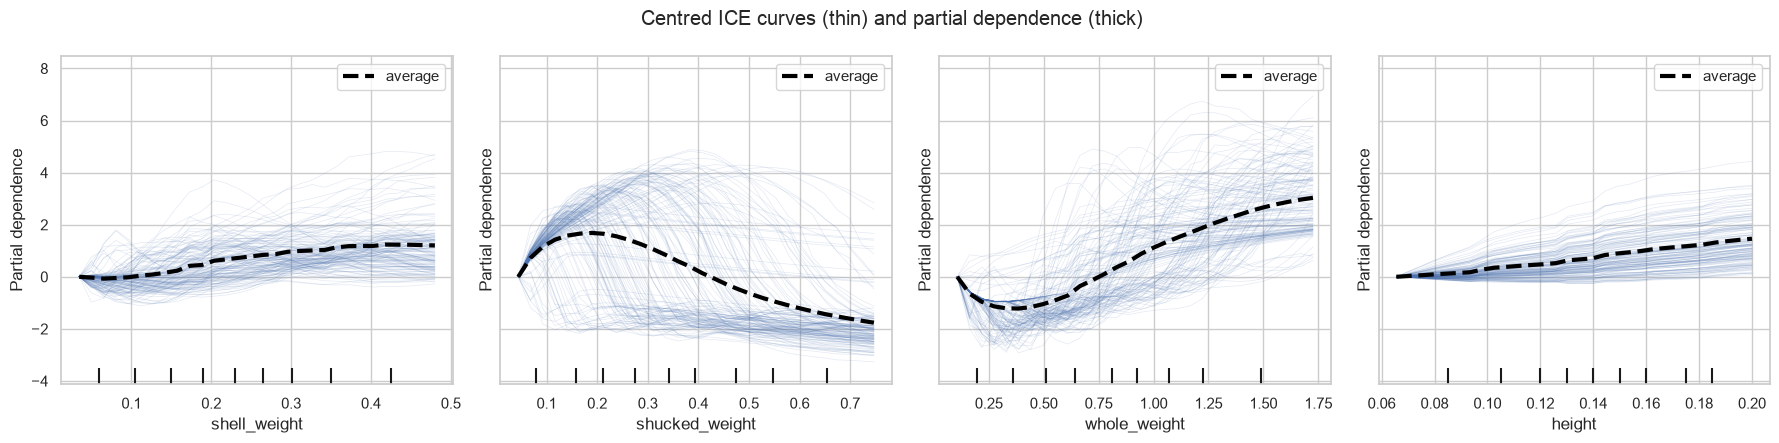

In [21]:
pdp_features = ["shell_weight", "shucked_weight", "whole_weight", "height"]
fig, axes = plt.subplots(1, len(pdp_features), figsize=(18, 4.5), sharey=True)
PartialDependenceDisplay.from_estimator(
    final_model,
    X_test,
    pdp_features,
    kind="both",
    centered=True,
    subsample=150,
    grid_resolution=30,
    random_state=RANDOM_STATE,
    ice_lines_kw={"alpha": 0.15},
    pd_line_kw={"color": "black", "linewidth": 3},
    ax=axes,
)
fig.suptitle("Centred ICE curves (thin) and partial dependence (thick)")
plt.tight_layout()
plt.show()

The main limit of the PDP and ICE curves is the **independence assumption**: setting one feature to a value while keeping the others creates artificial abalones, which can be physically impossible when the features are correlated (the course's example: a person 2 m tall weighing less than 50 kg). Here, the weights are strongly correlated, so a large part of the grid describes abalones whose meat is heavier than the whole abalone:

In [22]:
def share_of_impossible_points(
    features: pd.DataFrame, feature: str, grid: np.ndarray
) -> float:
    """Share of the PDP points where a part becomes heavier than the whole abalone."""
    impossible = 0
    for value in grid:
        modified = features.assign(**{feature: value})
        impossible += (
            modified[PART_WEIGHTS]
            .gt(modified["whole_weight"], axis=0)
            .any(axis=1)
            .sum()
        )
    return impossible / (len(features) * len(grid))


pd.Series(
    {
        feature: share_of_impossible_points(
            X_test,
            feature,
            np.linspace(
                X_test[feature].quantile(0.05), X_test[feature].quantile(0.95), 30
            ),
        )
        for feature in ["shucked_weight", "shell_weight", "whole_weight"]
    },
    name="share of impossible abalones in the PDP grid",
).round(3)

shucked_weight    0.231
shell_weight      0.141
whole_weight      0.171
Name: share of impossible abalones in the PDP grid, dtype: float64

**Conclusions**

- `shell_weight` and `height` have a monotonic, almost linear effect (about +1.2 and +1.5 rings over their range), and the ICE curves are nearly parallel: the effect is the same for every abalone.
- `whole_weight` increases the predicted age by about 3 rings above 0.4, with ICE curves that fan out: the effect is much stronger for some abalones than for others.
- `shucked_weight` is the most heterogeneous: on average, the prediction rises then falls by about 2 rings, but the ICE curves show two behaviours (curves that first rise by up to 4 rings, and curves that fall from the start). The PDP alone would hide this.
- However, 23% of the points used for the `shucked_weight` curves (14 to 17% for the other weights) are **physically impossible abalones** whose meat is heavier than the whole abalone. The decreasing part of the curve is largely computed in this zone, where the model never saw any data: it must be read with caution. ALE plots, which only use realistic variations, would be the next step.

## Exact Shapley values (SHAP)

Shapley values split the gap between the prediction for an abalone and the average prediction between the features, which are the players of a cooperative game. With the course's formula:

$$\phi_j(\hat f) = \sum_{S \subseteq \{x_1, \dots, x_p\} \setminus \{x_j\}} \frac{|S|!\,(p - 1 - |S|)!}{p!} \left[\hat f(S \cup \{x_j\}) - \hat f(S)\right]$$

where $\hat f(S)$ is the prediction when only the features in $S$ are known, the other ones being integrated out over their distribution (estimated with a background sample of the training set). The model only has $p = 8$ inputs, so there are $2^8 = 256$ coalitions and the values can be computed **exactly**, without the approximations of the `shap` package (KernelSHAP). The values of all the coalitions are computed once, then reused for the decomposition of the predictions (SHAP) and of the performance (XPER, below).

In [23]:
def predict_coalitions(
    model: BaseEstimator, instances: pd.DataFrame, background: pd.DataFrame
) -> np.ndarray:
    """Average prediction of each instance for every coalition of known features.

    Coalitions are encoded as bitmasks: feature j is known in coalition `mask` if
    bit j is set. The unknown features take the values of the background sample,
    and the predictions are averaged over it.
    """
    n_instances, n_background = len(instances), len(background)
    repeated = instances.iloc[np.repeat(np.arange(n_instances), n_background)]
    mixed_base = background.iloc[np.tile(np.arange(n_background), n_instances)]
    mixed_base = mixed_base.reset_index(drop=True)
    values = np.empty((n_instances, 2 ** len(FEATURES)))
    for mask in range(2 ** len(FEATURES)):
        mixed = mixed_base.copy()
        for j, feature in enumerate(FEATURES):
            if mask >> j & 1:
                mixed[feature] = repeated[feature].to_numpy()
        predictions = model.predict(mixed).reshape(n_instances, n_background)
        values[:, mask] = predictions.mean(axis=1)
    return values


def shapley_values(coalition_values: np.ndarray) -> np.ndarray:
    """Apply the Shapley formula to values indexed by coalition (last axis)."""
    n_players = int(np.log2(coalition_values.shape[-1]))
    phi = np.zeros((*coalition_values.shape[:-1], n_players))
    for j in range(n_players):
        for mask in range(2**n_players):
            if mask >> j & 1:
                continue
            size = bin(mask).count("1")
            weight = (
                math.factorial(size)
                * math.factorial(n_players - 1 - size)
                / math.factorial(n_players)
            )
            gain = coalition_values[..., mask | 1 << j] - coalition_values[..., mask]
            phi[..., j] += weight * gain
    return phi


explained = X_test.sample(N_EXPLAINED, random_state=RANDOM_STATE)
background = X_train.sample(N_BACKGROUND, random_state=RANDOM_STATE)
coalition_values = predict_coalitions(final_model, explained, background)
shap_values = pd.DataFrame(
    shapley_values(coalition_values), index=explained.index, columns=FEATURES
)

# Efficiency property: the contributions add up to the prediction minus the average
expected_prediction = coalition_values[:, 0]
efficiency_gap = shap_values.sum(axis=1) - (
    coalition_values[:, -1] - expected_prediction
)
print(f"Average prediction E[f(X)]: {expected_prediction.mean():.2f} rings")
print(f"Largest efficiency gap: {efficiency_gap.abs().max():.1e}")

Average prediction E[f(X)]: 10.21 rings
Largest efficiency gap: 1.8e-15


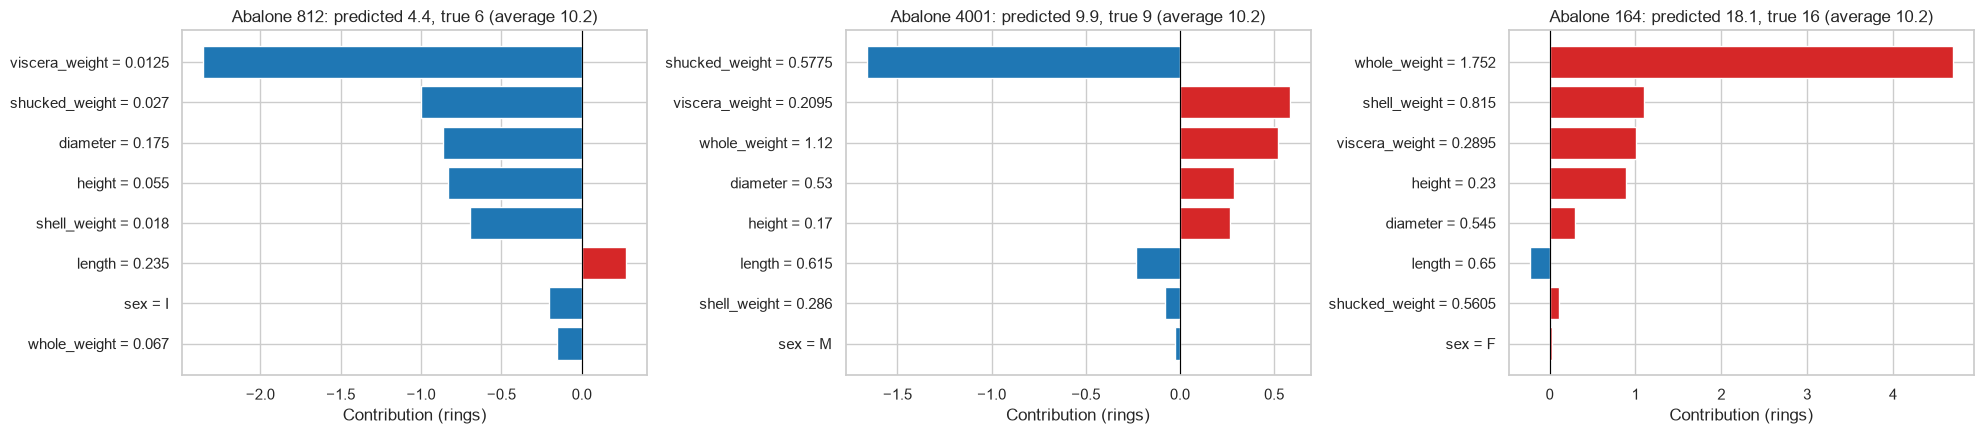

In [24]:
def plot_waterfall(abalone_id: int, ax: plt.Axes) -> None:
    """Plot the Shapley decomposition of the prediction for one abalone."""
    contributions = shap_values.loc[abalone_id].sort_values(key=abs)
    labels = [
        f"{feature} = {explained.loc[abalone_id, feature]}"
        for feature in contributions.index
    ]
    colors = np.where(contributions > 0, "tab:red", "tab:blue")
    ax.barh(labels, contributions, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    prediction = expected_prediction[0] + contributions.sum()
    ax.set(
        xlabel="Contribution (rings)",
        title=(
            f"Abalone {abalone_id}: predicted {prediction:.1f}, "
            f"true {y_test.loc[abalone_id]} (average {expected_prediction[0]:.1f})"
        ),
    )


predicted = pd.Series(coalition_values[:, -1], index=explained.index)
examples = [
    predicted.idxmin(),
    (predicted - predicted.median()).abs().idxmin(),
    predicted.idxmax(),
]
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for abalone_id, ax in zip(examples, axes, strict=True):
    plot_waterfall(abalone_id, ax)
plt.tight_layout()
plt.show()

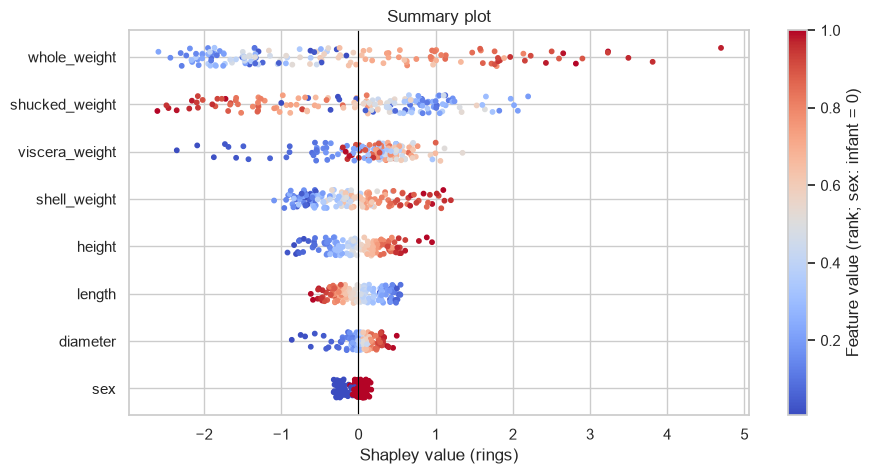

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
order = shap_values.abs().mean().sort_values().index
for position, feature in enumerate(order):
    values = explained[feature]
    if feature == CATEGORICAL_FEATURE:
        colors = values.eq("I").map({True: 0.0, False: 1.0})
    else:
        colors = values.rank(pct=True)
    jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.2, 0.2, len(values))
    scatter = ax.scatter(
        shap_values[feature], position + jitter, c=colors, cmap="coolwarm", s=10
    )
ax.set_yticks(range(len(order)), order)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Shapley value (rings)", title="Summary plot")
fig.colorbar(scatter, ax=ax, label="Feature value (rank; sex: infant = 0)")
plt.show()

**Conclusions**

- The efficiency property holds exactly (gap of order 1e-15): for every abalone, the contributions add up to the prediction minus the average prediction (10.2 rings).
- The three examples show complete local explanations: a young infant (predicted 4.4 rings, true 6) whose very low weights all pull the prediction down, an average abalone (9.9 predicted, 9 true) where heavy meat (-1.7 rings) offsets the other weights, and an old abalone (18.1 predicted, 16 true) driven by its whole weight (+4.7 rings).
- The summary plot recovers the EDA: heavy abalones are older (red points on the right for `whole_weight`, `shell_weight`, `height`), but **at equal whole weight, more meat means younger** (red points on the left for `shucked_weight`), and infants are younger (blue points on the left for `sex`).
- `length` receives negative contributions for large values, although it is positively correlated with age: this is a compensation between strongly collinear features (`length` and `diameter` have a 0.99 correlation), not a real effect. As the course warns, Shapley values integrate over the marginal distribution and inherit the problems of the PDP when the features are correlated.

## Explaining the performance: XPER

SHAP explains the predictions; XPER (Hué, Hurlin, Pérignon and Saurin) explains the **performance**: it applies the same Shapley formula to a performance metric, here the R² on the explained test abalones. The value of a coalition $S$ is the R² of the predictions $\hat f(S)$ in which only the features of $S$ are known, and the decomposition reads $R^2 = \phi_0 + \sum_j \phi_j$, where $\phi_0$ is the R² of a model that knows no feature. This is a simplified version of XPER, which reuses the coalition values computed for SHAP.

In [26]:
explained_target = y_test.loc[explained.index]
coalition_r2 = np.array(
    [
        r2_score(explained_target, coalition_values[:, mask])
        for mask in range(2 ** len(FEATURES))
    ]
)
xper = pd.Series(shapley_values(coalition_r2), index=FEATURES)
print(f"Benchmark phi_0 (no feature known): {coalition_r2[0]:.3f}")
print(f"R² of the model on these abalones: {coalition_r2[-1]:.3f}")
print(f"phi_0 + sum of the contributions: {coalition_r2[0] + xper.sum():.3f}")
xper.sort_values(ascending=False).round(3).rename("XPER contribution to R²")

Benchmark phi_0 (no feature known): -0.013
R² of the model on these abalones: 0.588
phi_0 + sum of the contributions: 0.588


whole_weight      0.260
shell_weight      0.148
viscera_weight    0.097
height            0.068
diameter          0.033
sex               0.017
shucked_weight    0.013
length           -0.036
Name: XPER contribution to R², dtype: float64

## The disagreement problem

The course stresses that different explanation methods applied to the same model can rank the features differently, because they rely on different assumptions and answer different questions. The four methods used so far are compared, each normalised to sum to 1:
- **permutation importance**: the increase in RMSE when the feature is shuffled (performance, test set);
- **SHAP importance**: $I_j = \frac{1}{n} \sum_i |\phi_j^{(i)}|$ (how much the feature moves the predictions);
- **XPER**: the contribution to the R² (performance);
- **surrogate tree**: the impurity-based importance of the global surrogate (what a simple imitation of the model uses).

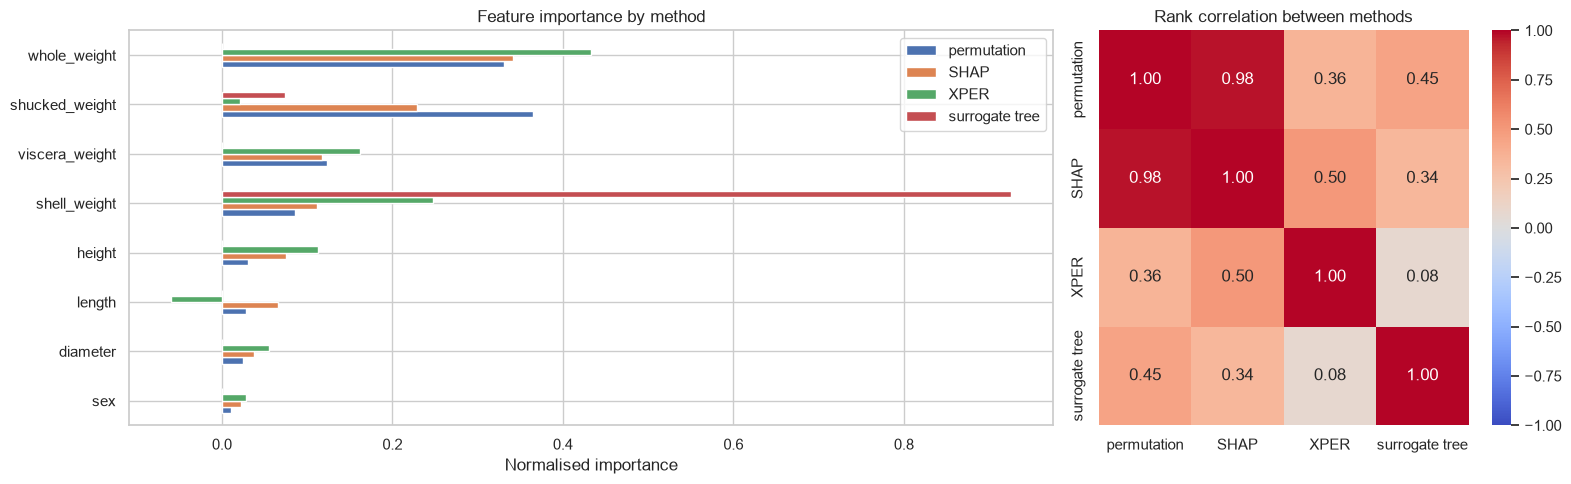

,permutation,SHAP,XPER,surrogate tree
sex,0.011,0.022,0.028,0.000
length,0.029,0.065,-0.060,0.000
diameter,0.025,0.037,0.055,0.000
height,0.031,0.076,0.113,0.000
whole_weight,0.331,0.342,0.433,0.000
shucked_weight,0.365,0.229,0.021,0.074
viscera_weight,0.123,0.117,0.162,0.000
shell_weight,0.086,0.111,0.247,0.926


In [27]:
def surrogate_importance(surrogate: Pipeline) -> pd.Series:
    """Impurity importance of the surrogate, the one-hot columns summed per feature."""
    importance = pd.Series(
        surrogate[-1].feature_importances_, index=surrogate[0].get_feature_names_out()
    )
    is_sex = importance.index.str.startswith(f"{CATEGORICAL_FEATURE}_")
    sex_importance = importance[is_sex].sum()
    return (
        importance[~is_sex]
        .reindex(FEATURES)
        .fillna({CATEGORICAL_FEATURE: sex_importance})
    )


importances = pd.DataFrame(
    {
        "permutation": pd.Series(importance.importances_mean, index=X_test.columns),
        "SHAP": shap_values.abs().mean(),
        "XPER": xper,
        "surrogate tree": surrogate_importance(surrogate),
    }
)
importances = importances / importances.sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 1]})
importances.sort_values("SHAP").plot.barh(ax=axes[0])
axes[0].set(xlabel="Normalised importance", title="Feature importance by method")
sns.heatmap(
    importances.corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title("Rank correlation between methods")
plt.tight_layout()
plt.show()
importances.round(3)

**Conclusions**

- **Permutation importance and SHAP agree** (rank correlation of 0.98): both rank `shucked_weight` and `whole_weight` far ahead.
- **XPER disagrees on `shucked_weight`**, which contributes almost nothing to the R² (0.013). The coalitions explain why: adding `shucked_weight` raises the R² by 0.30 on average when `whole_weight` is already known, but lowers it by 0.26 when it is not, because the true meat weight is then combined with the whole weight of another abalone, which creates unrealistic abalones. XPER averages over all coalitions, whereas permutation importance only removes one feature from the full model, where `whole_weight` is always known (the course's remark on slide 173).
- `length` has a **negative XPER contribution** (-0.036): it moves the predictions (SHAP) without improving the performance, which is the signature of a redundant feature.
- **The surrogate tree disagrees with everyone** (rank correlation of 0.08 to 0.45): with a fidelity of 0.72, its importance describes the tree more than the ensemble.
- What is robust across the methods: the weights matter much more than the size measurements and `sex`, and `whole_weight` is in the top two of every method except the surrogate. Any finer ranking depends on the method, which is why the course recommends reporting several methods with their assumptions rather than choosing one.

## Stability

Following Turney's definition, a learning algorithm is stable if two training sets drawn from the same population produce approximately the same model. Each model is refitted on 8 random subsamples of 80% of the training set, and two kinds of stability are measured on the test set:
- **stability of the predictions**: the standard deviation, across refits, of the prediction for the same abalone (an unstable model could give a different age to the same abalone after a simple retraining);
- **stability of the explanations**: the average distance $\lVert \varphi(f_1) - \varphi(f_2) \rVert_2$ between the normalised permutation importance vectors of two refits.

The subsamples are drawn without replacement: with bootstrap samples, duplicated rows would end up on both sides of the internal cross-validation of the stacking ensemble, which would bias it towards the models that memorise the training data.

In [28]:
def measure_stability(model: BaseEstimator) -> dict[str, float]:
    """Refit a model on subsamples and measure the variability of its outputs."""
    predictions, rmses, importance_vectors = [], [], []
    for seed in range(N_SUBSAMPLES):
        subsample = X_train.sample(frac=SUBSAMPLE_FRACTION, random_state=seed)
        refitted = clone(model).fit(subsample, y_train.loc[subsample.index])
        predictions.append(refitted.predict(X_test))
        rmses.append(root_mean_squared_error(y_test, predictions[-1]))
        permutation = permutation_importance(
            refitted,
            X_test,
            y_test,
            scoring="neg_root_mean_squared_error",
            n_repeats=3,
            random_state=RANDOM_STATE,
        ).importances_mean
        importance_vectors.append(permutation / permutation.sum())
    prediction_std = np.std(predictions, axis=0)
    distances = [
        np.linalg.norm(first - second)
        for first, second in itertools.combinations(importance_vectors, 2)
    ]
    return {
        "test rmse": np.mean(rmses),
        "prediction std (mean)": prediction_std.mean(),
        "prediction std (90th pct)": np.quantile(prediction_std, 0.9),
        "importance distance": np.mean(distances),
    }


stability_models = {
    "linear regression": baseline_models["linear regression"],
    **tuned_models,
    "stacking ensemble": stacking_model,
}
stability = pd.DataFrame(
    {name: measure_stability(model) for name, model in stability_models.items()}
).T
stability.round(3)

,test rmse,prediction std (mean),prediction std (90th pct),importance distance
linear regression,2.242,0.063,0.099,0.040
"svr (log, tuned)",2.126,0.135,0.241,0.031
"ridge on splines (log, tuned)",2.121,0.086,0.138,0.058
random forest (tuned),2.082,0.136,0.237,0.023
gradient boosting (tuned),2.103,0.212,0.388,0.040
stacking ensemble,2.087,0.108,0.184,0.064


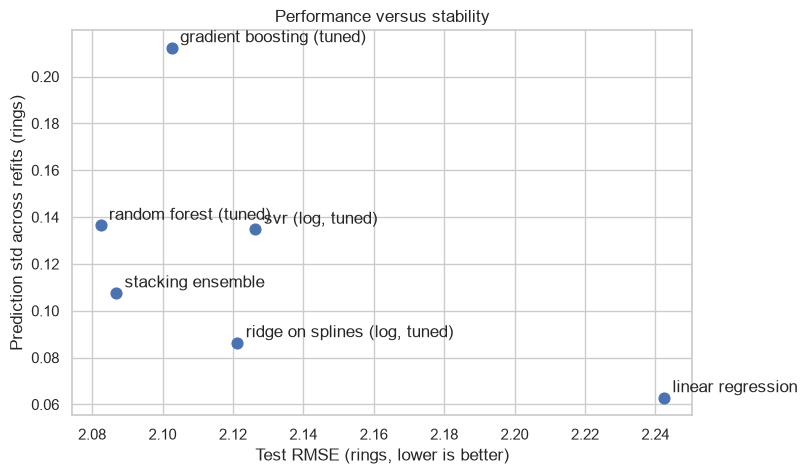

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(stability["test rmse"], stability["prediction std (mean)"], s=60)
for name, row in stability.iterrows():
    ax.annotate(
        name,
        (row["test rmse"], row["prediction std (mean)"]),
        textcoords="offset points",
        xytext=(6, 4),
    )
ax.set(
    xlabel="Test RMSE (rings, lower is better)",
    ylabel="Prediction std across refits (rings)",
    title="Performance versus stability",
)
plt.show()

**Conclusions**

- The **linear regression is the most stable** model (its predictions vary by 0.06 rings on average across refits), but also the least accurate (RMSE of 2.24): the performance versus stability trade-off of the course.
- The **stacking ensemble is more stable than its non-linear components** (0.11 rings, versus 0.14 for the SVR and the random forest and 0.21 for gradient boosting): averaging models that make different errors also averages their variations. Only the ridge on splines is more stable (0.09).
- For 90% of the abalones, retraining the ensemble on another subsample changes the prediction by less than 0.18 rings, which is small compared with its average error (1.5 rings): the model would not change its mind on an abalone after a simple retraining.
- Its **explanations are less stable** (the largest distance between importance vectors, 0.064, versus 0.023 for the random forest): the split of the importance between the correlated weights varies from one refit to the other. The overall ranking of the weights is stable, but the exact shares should not be over-interpreted.
- When refitted on 80% of the data, the tuned random forest is as accurate as the ensemble (2.082 versus 2.087). The ensemble keeps the best cross-validated score and better-balanced errors, but the gap between the two is within the noise.

## Fairness of the errors across groups

Abalones have no protected attribute in the legal sense, but the fairness tests of the course transpose to a question that matters here: **are the errors of the model the same for every group of abalones?** A model that is systematically biased for one group would mislead any decision based on it (e.g. fishing quotas based on the age of the population). With `sex` as the group attribute $D$, three null hypotheses are tested with Welch's t-test (model agnostic: they only use $\hat Y$, $Y$ and $D$):
- **bias parity**: the mean residual is the same in both groups;
- **accuracy parity**: the mean absolute error is the same in both groups;
- **separation** (errors independent of the group given the true age $Y$): the residual, net of its average within its age band, is the same in both groups.

As the course warns, not rejecting a null hypothesis does not prove that the model is fair: it only means that the test found no evidence of unfairness.

In [30]:
def error_parity_tests(
    residuals: pd.Series, groups: pd.Series, first: str, second: str
) -> pd.Series:
    """Test the equality of the errors between two groups (Welch p-values)."""
    age_band = pd.qcut(y_test.loc[residuals.index], 5, duplicates="drop")
    residuals_given_age = residuals - residuals.groupby(
        age_band, observed=True
    ).transform("mean")
    errors = {
        "bias parity": residuals,
        "accuracy parity": residuals.abs(),
        "separation": residuals_given_age,
    }
    in_first, in_second = groups == first, groups == second
    return pd.Series(
        {
            test: ttest_ind(error[in_first], error[in_second], equal_var=False).pvalue
            for test, error in errors.items()
        }
    )


age_group = X_test["sex"].eq("I").map({True: "infant", False: "adult"})
fairness_tests = pd.DataFrame(
    {
        "male vs female": error_parity_tests(residuals, X_test["sex"], "M", "F"),
        "infant vs adult": error_parity_tests(residuals, age_group, "infant", "adult"),
    }
).T
fairness_tests.round(4)

,bias parity,accuracy parity,separation
male vs female,0.7506,0.0432,0.4431
infant vs adult,0.8038,0.0000,0.0000


**Conclusions**

- **Males versus females**: the bias parity is not rejected (p = 0.75), but the accuracy parity is rejected at the 5% level (p = 0.043): the errors are larger for females (MAE of 1.87 versus 1.59 rings). The separation test is not rejected (p = 0.44): **once the true age is taken into account, the errors are the same for both sexes**. The gap comes from the fact that females are older on average (11.2 versus 10.7 rings) and that errors grow with age, not from a different treatment by the model. The p-value of 0.043 is also borderline given that six tests are run.
- **Infants versus adults**: the overall bias is the same (p = 0.80), but the accuracy and separation parities are clearly rejected (p < 0.0001). At equal true age, the model **underestimates infants** (residual of +0.58 rings net of the age band) **and overestimates adults** (-0.26): it relies on size, and at the same age an infant is smaller than an adult.
- As in the course's example, the conclusion depends on the definition of fairness: the model is fair between males and females in the sense of separation, not of accuracy parity. The bias of infants versus adults at equal age is a concrete lead for improvement (interactions between `sex` and the weights, or a model per group), to be checked with these same tests.

# Summary and next steps

| | Linear regression (baseline) | Stacking ensemble (final model) |
|---|---|---|
| Cleaning | 10 impossible rows removed | 10 impossible rows removed |
| Features | raw measurements + one-hot `sex` | + weight ratios, log of the measurements |
| Model | `LinearRegression` | SVR + ridge on splines + random forest + gradient boosting, combined by a Ridge |

**Key results**
1. The final model reduces the test RMSE by about 7% (2.24 → 2.09 rings) and the MAE by about 8% compared with the linear regression baseline. The gain is real but modest: the dataset sets a ceiling, since the measurements carry little information about the age of mature abalones. All the tuned model families end up within 0.02 rings of each other.
2. The errors are small for infants and young abalones, and large for old ones, which the model systematically underestimates.
3. The key information is the composition of the weight (share of meat versus whole weight) rather than the size of the abalone.
4. The ISAF analysis shows that this conclusion is robust across explanation methods, but that the exact ranking of the features is not: `shucked_weight` is only useful together with `whole_weight`, and methods that integrate over the marginal distribution (PDP, SHAP) partly rely on physically impossible abalones.
5. The ensemble is more stable than each of its non-linear components, and its errors are the same for males and females at equal age. It does, however, underestimate infants and overestimate adults of the same age.

**For the next step (from notebooks to modules)**
- The whole model is a single scikit-learn pipeline, so the encoder and the feature engineering are saved with it: the training module only has to load, clean, split, fit and save one object, and the inference module only has to load it and call `predict`.
- `load_data`, `clean_data`, `split_data`, `add_weight_ratios`, `log_measurements`, `build_preprocessor` and `build_stacking_model` can be moved as-is to Python modules, with the tuned hyperparameters hard-coded instead of re-running the search at every training.
- The rules of `find_invalid_rows` can be reused to validate the inputs of the API with Pydantic. This is required, not optional: an abalone with a height of 0 makes the model crash (log of 0).
- The infant versus adult bias at equal age is the main lead to improve the model.